In [1]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# 디렉토리 경로
dir1 = 'dataset/with_mask'
dir2 = 'dataset/without_mask'

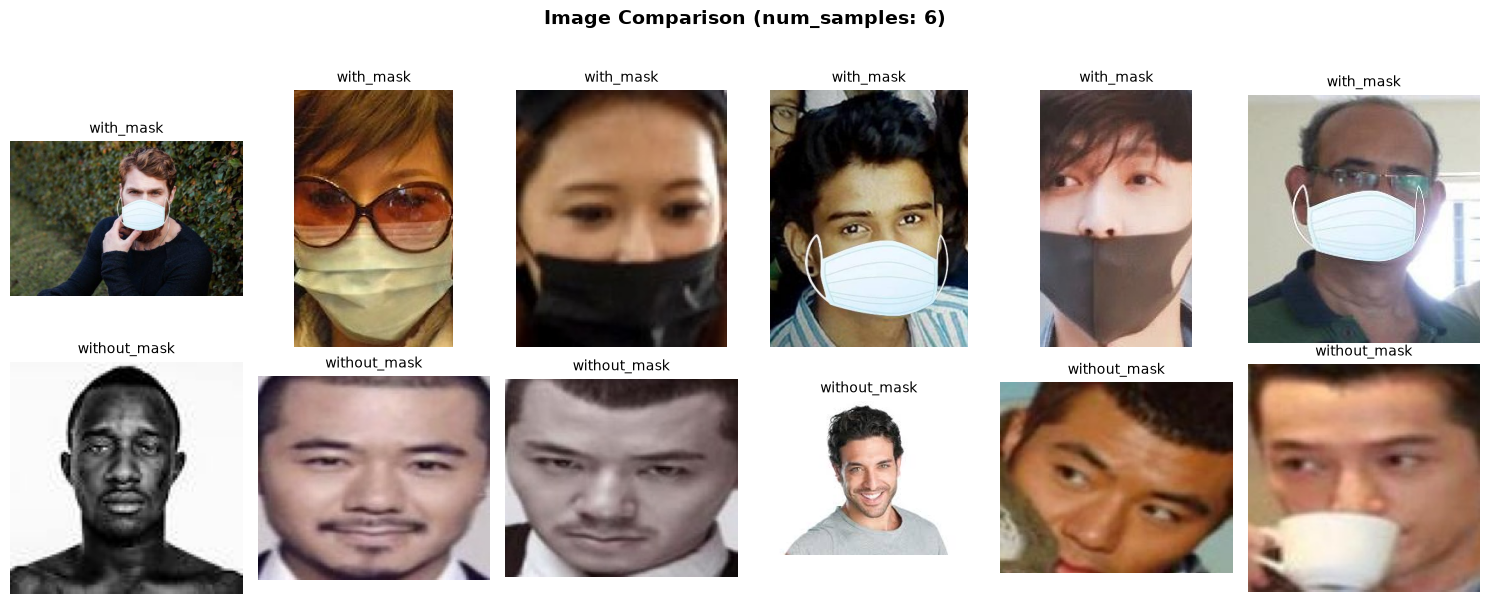

In [2]:
# 처음 몇 개 파일만 선택해서 위아래 비교
num_samples = 6

# 각 디렉토리에서 파일 선택
files1 = sorted(os.listdir(dir1))[:num_samples]
files2 = sorted(os.listdir(dir2))[:num_samples]

# 2 * num_samples 그리드 (위: dir1/with_mask, 아래: dir2/without_mask)
fig, axes = plt.subplots(2, num_samples, figsize=(15, 6))

for idx in range(num_samples):
    # 위: dataset/with_mask (dir1)
    img1 = Image.open(os.path.join(dir1, files1[idx]))
    axes[0, idx].imshow(img1)
    axes[0, idx].set_title('with_mask', fontsize=10)
    axes[0, idx].axis('off')
    
    # 아래: dataset/without_mask (dir2)
    img2 = Image.open(os.path.join(dir2, files2[idx]))
    axes[1, idx].imshow(img2)
    axes[1, idx].set_title('without_mask', fontsize=10)
    axes[1, idx].axis('off')

# y축 레이블 추가
axes[0, 0].set_ylabel('with_mask', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('without_mask', fontsize=12, fontweight='bold')

plt.suptitle(f'Image Comparison (num_samples: {num_samples})', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

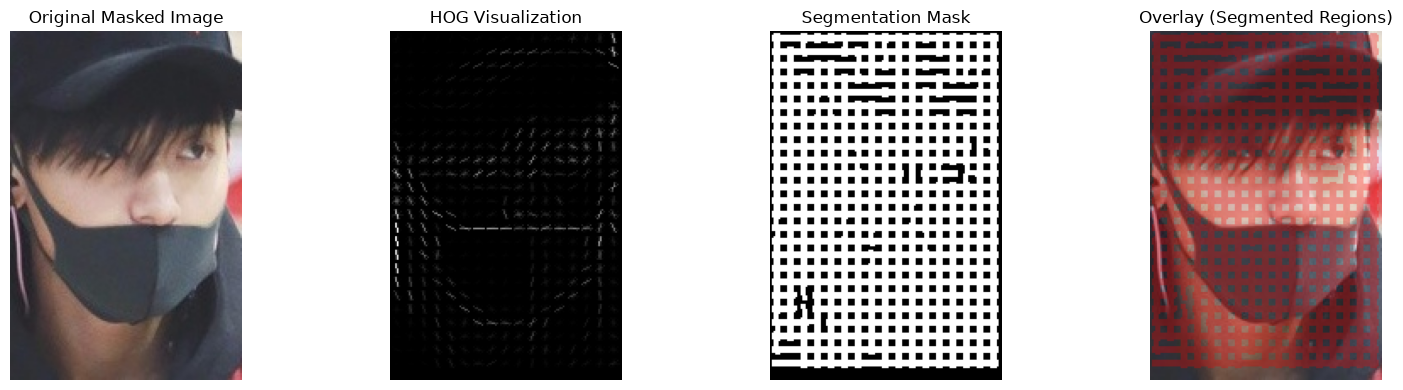

HOG 특성 차원: (13824,)
세그먼테이션 마스크 크기: (206, 137)
세그먼테이션된 영역 비율: 68.54%


In [7]:
from skimage.feature import hog
from scipy import ndimage

def segment_with_hog(img_array, pixels_per_cell=(8, 8), cells_per_block=(2, 2)):
    """
    HOG를 사용해 마스크 영역을 segmentation
    
    Parameters:
    - img_array: PIL Image 또는 numpy array
    - pixels_per_cell: HOG 셀 크기
    - cells_per_block: HOG 블록 크기
    
    Returns:
    - hog_features: HOG 특성
    - hog_image: HOG 시각화 이미지
    - mask: 마스크된 영역 (이진)
    """
    # PIL Image를 numpy array로 변환
    if hasattr(img_array, 'convert'):
        img_gray = np.array(img_array.convert('L'))
    else:
        img_gray = np.array(img_array)
        if len(img_gray.shape) == 3:  # RGB 이미지인 경우
            img_gray = np.dot(img_gray[..., :3], [0.299, 0.587, 0.114])
    
    # HOG 계산
    hog_features, hog_image = hog(img_gray, 
                                   pixels_per_cell=pixels_per_cell,
                                   cells_per_block=cells_per_block,
                                   visualize=True)
    
    # HOG 이미지를 정규화
    hog_normalized = (hog_image - hog_image.min()) / (hog_image.max() - hog_image.min() + 1e-5)
    
    # 임계값으로 마스크 생성 (HOG 응답이 높은 영역 = 에지/특징이 있는 영역)
    threshold = np.percentile(hog_normalized, 60)
    mask = hog_normalized > threshold
    
    # 모폴로지 연산으로 노이즈 제거
    mask = ndimage.binary_closing(mask, structure=np.ones((3, 3)))
    mask = ndimage.binary_opening(mask, structure=np.ones((3, 3)))
    
    return hog_features, hog_image, mask.astype(np.uint8) * 255

# 테스트: 첫 번째 마스크 이미지로 시연
test_filename = 'dataset/with_mask/with_mask_157.jpg'
test_img = Image.open(test_filename)
hog_feat, hog_vis, seg_mask = segment_with_hog(test_img)

# 결과 시각화
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(test_img)
axes[0].set_title('Original Masked Image')
axes[0].axis('off')

axes[1].imshow(hog_vis, cmap='gray')
axes[1].set_title('HOG Visualization')
axes[1].axis('off')

axes[2].imshow(seg_mask, cmap='gray')
axes[2].set_title('Segmentation Mask')
axes[2].axis('off')

# 오버레이
img_array = np.array(test_img)
overlay = img_array.copy()
overlay[seg_mask > 0] = overlay[seg_mask > 0] * 0.7 + np.array([255, 0, 0]) * 0.3
axes[3].imshow(overlay.astype(np.uint8))
axes[3].set_title('Overlay (Segmented Regions)')
axes[3].axis('off')

plt.tight_layout()
plt.show()

print(f"HOG 특성 차원: {hog_feat.shape}")
print(f"세그먼테이션 마스크 크기: {seg_mask.shape}")
print(f"세그먼테이션된 영역 비율: {(seg_mask > 0).sum() / seg_mask.size * 100:.2f}%")

In [20]:
import pandas as pd
from skimage.feature import hog
from scipy import ndimage

def compute_image_statistics(img_path):
    """Compute various statistics of an image"""
    img = Image.open(img_path)
    img_array = np.array(img)
    
    # Convert to grayscale
    if len(img_array.shape) == 3:
        img_gray = np.dot(img_array[..., :3], [0.299, 0.587, 0.114])
    else:
        img_gray = img_array
    
    # HOG edge features
    hog_features, _ = hog(img_gray, pixels_per_cell=(8, 8), 
                          cells_per_block=(2, 2), visualize=True)
    
    # Edge detection (Sobel)
    sx = ndimage.sobel(img_gray, axis=0)
    sy = ndimage.sobel(img_gray, axis=1)
    edges = np.sqrt(sx**2 + sy**2)
    
    # Calculate statistics
    stats = {
        'mean': img_gray.mean(),
        'std': img_gray.std(),
        'min': img_gray.min(),
        'max': img_gray.max(),
        'median': np.median(img_gray),
        'percentile_25': np.percentile(img_gray, 25),
        'percentile_75': np.percentile(img_gray, 75),
        'hog_features': len(hog_features),
        'edge_mean': edges.mean(),
        'edge_std': edges.std(),
        'brightness_variance': np.var(img_gray),
    }
    
    return stats

# Calculate statistics for all files
print("Computing image statistics... (this may take a moment)")

stats_masked = []
stats_unmasked = []

for i, (file1, file2) in enumerate(zip(files1, files2)):
    # Masked images (with_mask)
    stats_m = compute_image_statistics(os.path.join(dir1, file1))
    stats_m['filename'] = file1
    stats_masked.append(stats_m)
    
    # Unmasked images (without_mask)
    stats_u = compute_image_statistics(os.path.join(dir2, file2))
    stats_u['filename'] = file2
    stats_unmasked.append(stats_u)

df_masked = pd.DataFrame(stats_masked)
df_unmasked = pd.DataFrame(stats_unmasked)

print("\n=== with_mask Images Statistics ===")
print(df_masked[['filename', 'mean', 'std', 'edge_mean']].to_string(index=False))

print("\n=== without_mask Images Statistics ===")
print(df_unmasked[['filename', 'mean', 'std', 'edge_mean']].to_string(index=False))

# Comparison statistics
print("\n=== Mean Comparison ===")
comparison = pd.DataFrame({
    'with_mask': df_masked[['mean', 'std', 'edge_mean']].mean(),
    'without_mask': df_unmasked[['mean', 'std', 'edge_mean']].mean(),
})
comparison['difference'] = comparison['with_mask'] - comparison['without_mask']
comparison['difference_pct'] = (comparison['difference'] / comparison['without_mask'] * 100).round(2)
print(comparison)

Computing image statistics... (this may take a moment)

=== with_mask Images Statistics ===
          filename       mean       std  edge_mean
   with_mask_1.jpg  65.427252 53.855910  53.979307
  with_mask_10.jpg 101.338458 54.275554  65.827531
 with_mask_100.jpg  83.413899 62.852206  70.079212
with_mask_1000.jpg 101.549503 86.229898  52.795793
with_mask_1001.jpg 120.599745 59.927612  43.403695
with_mask_1002.jpg 154.575093 67.980368  38.597883

=== without_mask Images Statistics ===
             filename       mean       std  edge_mean
   without_mask_1.jpg 156.040500 99.614055 102.521690
  without_mask_10.jpg 142.016421 47.170602  66.843011
 without_mask_100.jpg 123.971706 49.831563  62.260513
without_mask_1000.jpg 220.927397 59.759195  32.913112
without_mask_1001.jpg  96.996294 45.016274  48.421384
without_mask_1002.jpg 139.757392 54.436404  45.777024

=== Mean Comparison ===
            with_mask  without_mask  difference  difference_pct
mean       104.483992    146.618285  -42.134

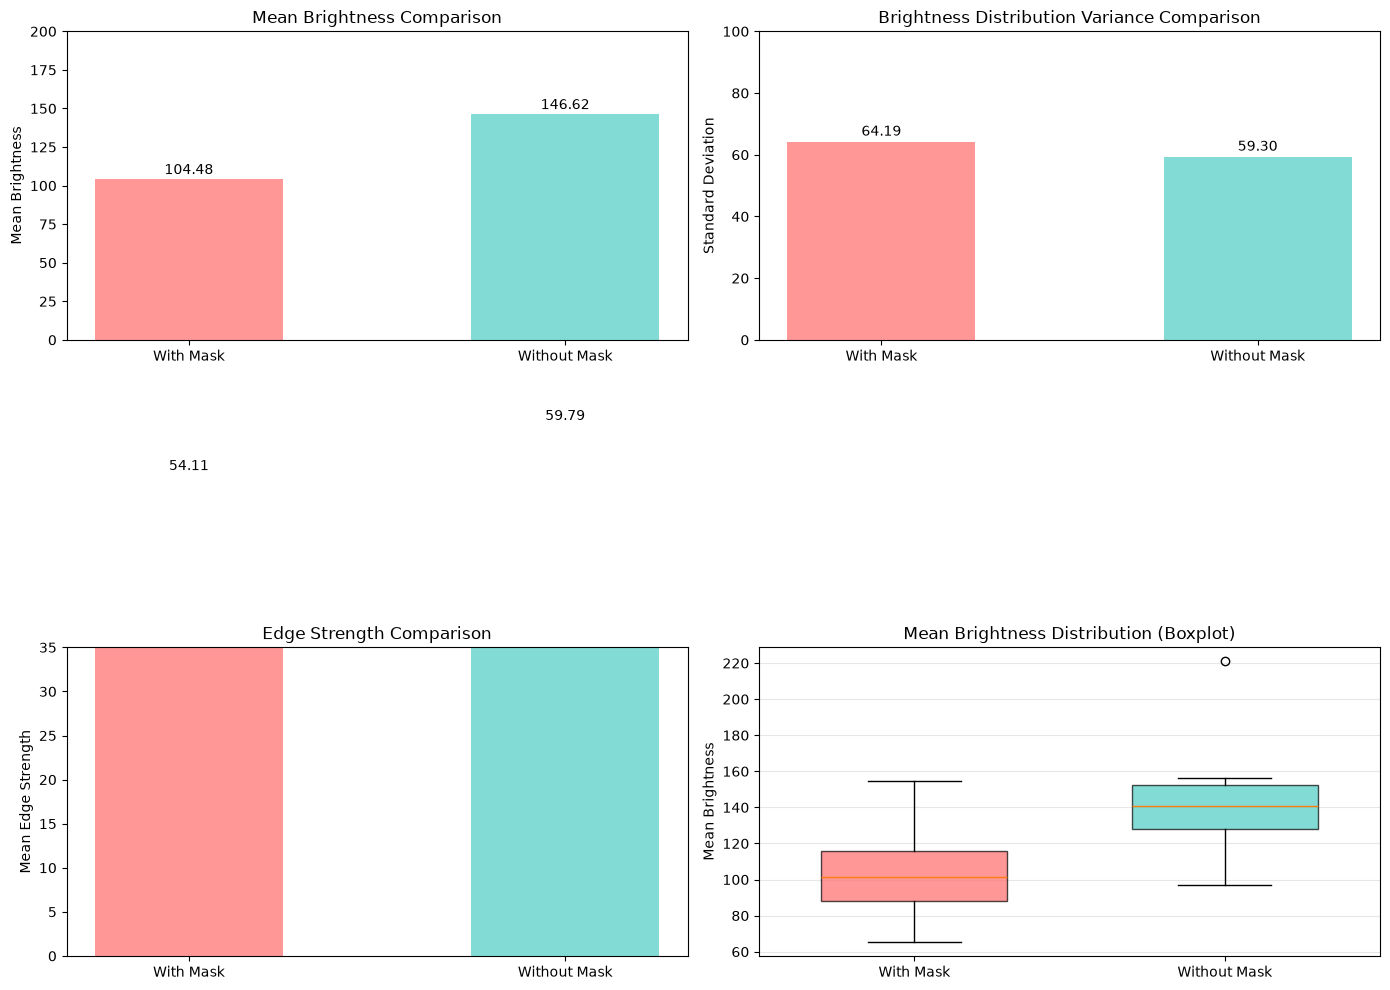


=== Detailed Statistical Analysis ===

Masked Images:
  - Mean Brightness: 104.48 ± 30.84
  - Standard Deviation: 64.19 ± 12.04
  - Edge Strength: 54.11 ± 12.24

Unmasked Images:
  - Mean Brightness: 146.62 ± 41.60
  - Standard Deviation: 59.30 ± 20.44
  - Edge Strength: 59.79 ± 24.21

Interpretation:
  - Masked images are approximately -28.74% brighter
  - Edge characteristics show minimal difference (-9.49%)


In [22]:
# Visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Mean brightness comparison
axes[0, 0].bar(['With Mask', 'Without Mask'], 
               [df_masked['mean'].mean(), df_unmasked['mean'].mean()],
               color=['#FF6B6B', '#4ECDC4'], alpha=0.7, width=0.5)
axes[0, 0].set_ylabel('Mean Brightness')
axes[0, 0].set_title('Mean Brightness Comparison')
axes[0, 0].set_ylim(0, 200)
for i, v in enumerate([df_masked['mean'].mean(), df_unmasked['mean'].mean()]):
    axes[0, 0].text(i, v + 3, f'{v:.2f}', ha='center')

# 2. Standard deviation comparison
axes[0, 1].bar(['With Mask', 'Without Mask'], 
               [df_masked['std'].mean(), df_unmasked['std'].mean()],
               color=['#FF6B6B', '#4ECDC4'], alpha=0.7, width=0.5)
axes[0, 1].set_ylabel('Standard Deviation')
axes[0, 1].set_title('Brightness Distribution Variance Comparison')
axes[0, 1].set_ylim(0, 100)
for i, v in enumerate([df_masked['std'].mean(), df_unmasked['std'].mean()]):
    axes[0, 1].text(i, v + 2, f'{v:.2f}', ha='center')

# 3. Edge mean comparison
axes[1, 0].bar(['With Mask', 'Without Mask'], 
               [df_masked['edge_mean'].mean(), df_unmasked['edge_mean'].mean()],
               color=['#FF6B6B', '#4ECDC4'], alpha=0.7, width=0.5)
axes[1, 0].set_ylabel('Mean Edge Strength')
axes[1, 0].set_title('Edge Strength Comparison')
axes[1, 0].set_ylim(0, 35)
for i, v in enumerate([df_masked['edge_mean'].mean(), df_unmasked['edge_mean'].mean()]):
    axes[1, 0].text(i, v + 1, f'{v:.2f}', ha='center')

# 4. Boxplot (mean brightness)
box_data = [df_masked['mean'].values, df_unmasked['mean'].values]
bp = axes[1, 1].boxplot(box_data, patch_artist=True, widths=0.6)
axes[1, 1].set_xticklabels(['With Mask', 'Without Mask'])
for patch, color in zip(bp['boxes'], ['#FF6B6B', '#4ECDC4']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[1, 1].set_ylabel('Mean Brightness')
axes[1, 1].set_title('Mean Brightness Distribution (Boxplot)')
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("\n=== Detailed Statistical Analysis ===")
print(f"\nMasked Images:")
print(f"  - Mean Brightness: {df_masked['mean'].mean():.2f} ± {df_masked['mean'].std():.2f}")
print(f"  - Standard Deviation: {df_masked['std'].mean():.2f} ± {df_masked['std'].std():.2f}")
print(f"  - Edge Strength: {df_masked['edge_mean'].mean():.2f} ± {df_masked['edge_mean'].std():.2f}")

print(f"\nUnmasked Images:")
print(f"  - Mean Brightness: {df_unmasked['mean'].mean():.2f} ± {df_unmasked['mean'].std():.2f}")
print(f"  - Standard Deviation: {df_unmasked['std'].mean():.2f} ± {df_unmasked['std'].std():.2f}")
print(f"  - Edge Strength: {df_unmasked['edge_mean'].mean():.2f} ± {df_unmasked['edge_mean'].std():.2f}")

print(f"\nInterpretation:")
print(f"  - Masked images are approximately {comparison.loc['mean', 'difference_pct']:.2f}% brighter")
print(f"  - Edge characteristics show minimal difference ({comparison.loc['edge_mean', 'difference_pct']:.2f}%)")

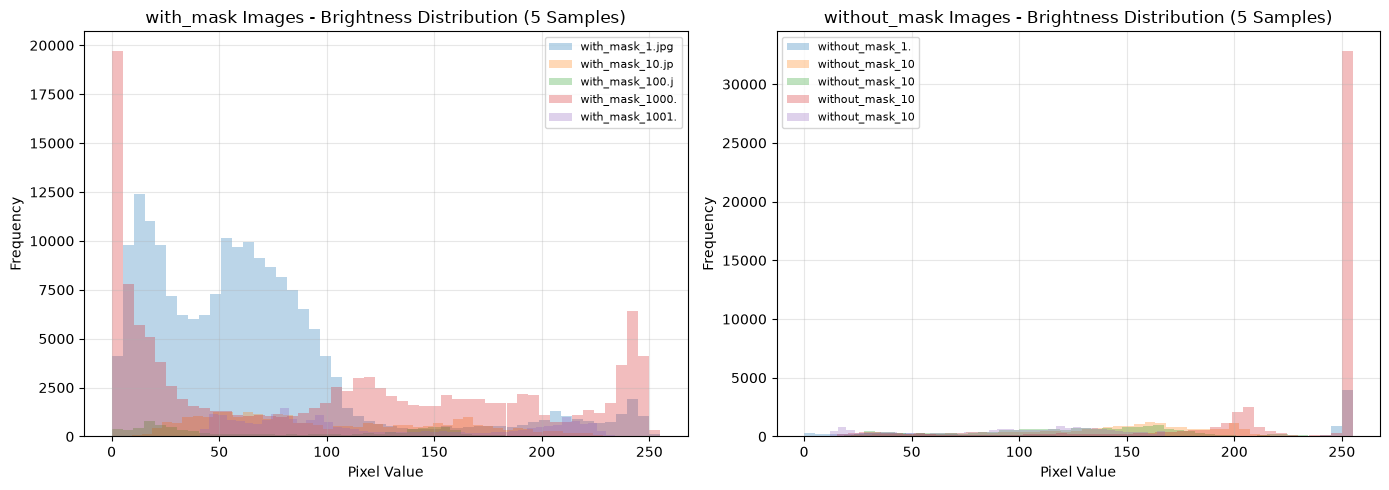


=== Detailed Statistics for All Files ===
         with_mask          without_mask  with_mask_mean  without_mask_mean  brightness_diff  with_mask_edge  without_mask_edge  brightness_diff_pct
   with_mask_1.jpg    without_mask_1.jpg       65.427252         156.040500       -90.613248       53.979307         102.521690               -58.07
  with_mask_10.jpg   without_mask_10.jpg      101.338458         142.016421       -40.677964       65.827531          66.843011               -28.64
 with_mask_100.jpg  without_mask_100.jpg       83.413899         123.971706       -40.557807       70.079212          62.260513               -32.72
with_mask_1000.jpg without_mask_1000.jpg      101.549503         220.927397      -119.377894       52.795793          32.913112               -54.03
with_mask_1001.jpg without_mask_1001.jpg      120.599745          96.996294        23.603451       43.403695          48.421384                24.33
with_mask_1002.jpg without_mask_1002.jpg      154.575093       

In [24]:
# Histogram comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# with_mask images histogram
for filename in df_masked['filename'].values[:5]:
    img = Image.open(os.path.join(dir1, filename))
    img_gray = np.array(img.convert('L'))
    axes[0].hist(img_gray.flatten(), bins=50, alpha=0.3, label=filename[:15])

axes[0].set_xlabel('Pixel Value')
axes[0].set_ylabel('Frequency')
axes[0].set_title('with_mask Images - Brightness Distribution (5 Samples)')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# without_mask images histogram
for filename in df_unmasked['filename'].values[:5]:
    img = Image.open(os.path.join(dir2, filename))
    img_gray = np.array(img.convert('L'))
    axes[1].hist(img_gray.flatten(), bins=50, alpha=0.3, label=filename[:15])

axes[1].set_xlabel('Pixel Value')
axes[1].set_ylabel('Frequency')
axes[1].set_title('without_mask Images - Brightness Distribution (5 Samples)')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Print combined dataframe
print("\n=== Detailed Statistics for All Files ===")
combined_df = pd.DataFrame({
    'with_mask': df_masked['filename'].values,
    'without_mask': df_unmasked['filename'].values,
    'with_mask_mean': df_masked['mean'].values,
    'without_mask_mean': df_unmasked['mean'].values,
    'brightness_diff': (df_masked['mean'].values - df_unmasked['mean'].values),
    'with_mask_edge': df_masked['edge_mean'].values,
    'without_mask_edge': df_unmasked['edge_mean'].values,
})
combined_df['brightness_diff_pct'] = (combined_df['brightness_diff'] / combined_df['without_mask_mean'] * 100).round(2)
print(combined_df.to_string(index=False))

In [10]:
    # 4) ROC-AUC 성능 상세
    bp = axes[1, 1].boxplot([scores_hog, scores_color, scores_combined], 
                            patch_artist=True)
    axes[1, 1].set_xticklabels(['HOG', '색상', 'HOG+색상'])
    for patch, color in zip(bp['boxes'], ['#FF6B6B', '#4ECDC4', '#45B7D1']):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    axes[1, 1].set_ylabel('ROC-AUC Score', fontsize=12, fontweight='bold')
    axes[1, 1].set_title('Cross-Validation 성능 분포', fontsize=13, fontweight='bold')
    axes[1, 1].set_ylim([0, 1])
    axes[1, 1].grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()

    # 최종 결론
    print("\n" + "=" * 80)
    print("결론 및 해석")
    print("=" * 80)
    auc_threshold = 0.6
    if scores_combined.mean() > auc_threshold:
        print(f"✓ 두 클래스는 HOG와 색상 피쳐로 충분히 구분됩니다! (ROC-AUC: {scores_combined.mean():.3f})")
    elif scores_combined.mean() > 0.5:
        print(f"△ 두 클래스는 어느 정도 구분 가능합니다. (ROC-AUC: {scores_combined.mean():.3f})")
    else:
        print(f"✗ 두 클래스는 현재 피쳐로는 구분이 어렵습니다. (ROC-AUC: {scores_combined.mean():.3f})")
        
    print(f"\n  - HOG 피쳐의 판별력: {scores_hog.mean():.3f}")
    print(f"  - 색상 피쳐의 판별력: {scores_color.mean():.3f}")
    print(f"  - 결합 피쳐의 판별력: {scores_combined.mean():.3f}")
    print(f"  - 유의미한 HOG 차원: {hog_significant}/{len(hog_pvalues)}")
    print(f"  - 유의미한 색상 차원: {color_significant}/{len(color_pvalues)}")
    print(f"\n💡 추천: ", end="")
    if scores_combined.mean() < 0.55:
        print("추가 피쳐 추출이 필요합니다 (예: LBP, SIFT, 딥러닝 특성)")
    elif scores_color.mean() > scores_hog.mean():
        print("색상 정보가 더 중요합니다!")
    else:
        print("HOG와 색상 정보의 조합이 유효합니다!")

<Figure size 640x480 with 0 Axes>


결론 및 해석
✓ 두 클래스는 HOG와 색상 피쳐로 충분히 구분됩니다! (ROC-AUC: 1.000)

  - HOG 피쳐의 판별력: 0.792
  - 색상 피쳐의 판별력: 0.417
  - 결합 피쳐의 판별력: 1.000
  - 유의미한 HOG 차원: 5/20
  - 유의미한 색상 차원: 1/96

💡 추천: HOG와 색상 정보의 조합이 유효합니다!


HOG, Color, and Combined Features based Segmentation Visualization

[1] with_mask - with_mask_1.jpg


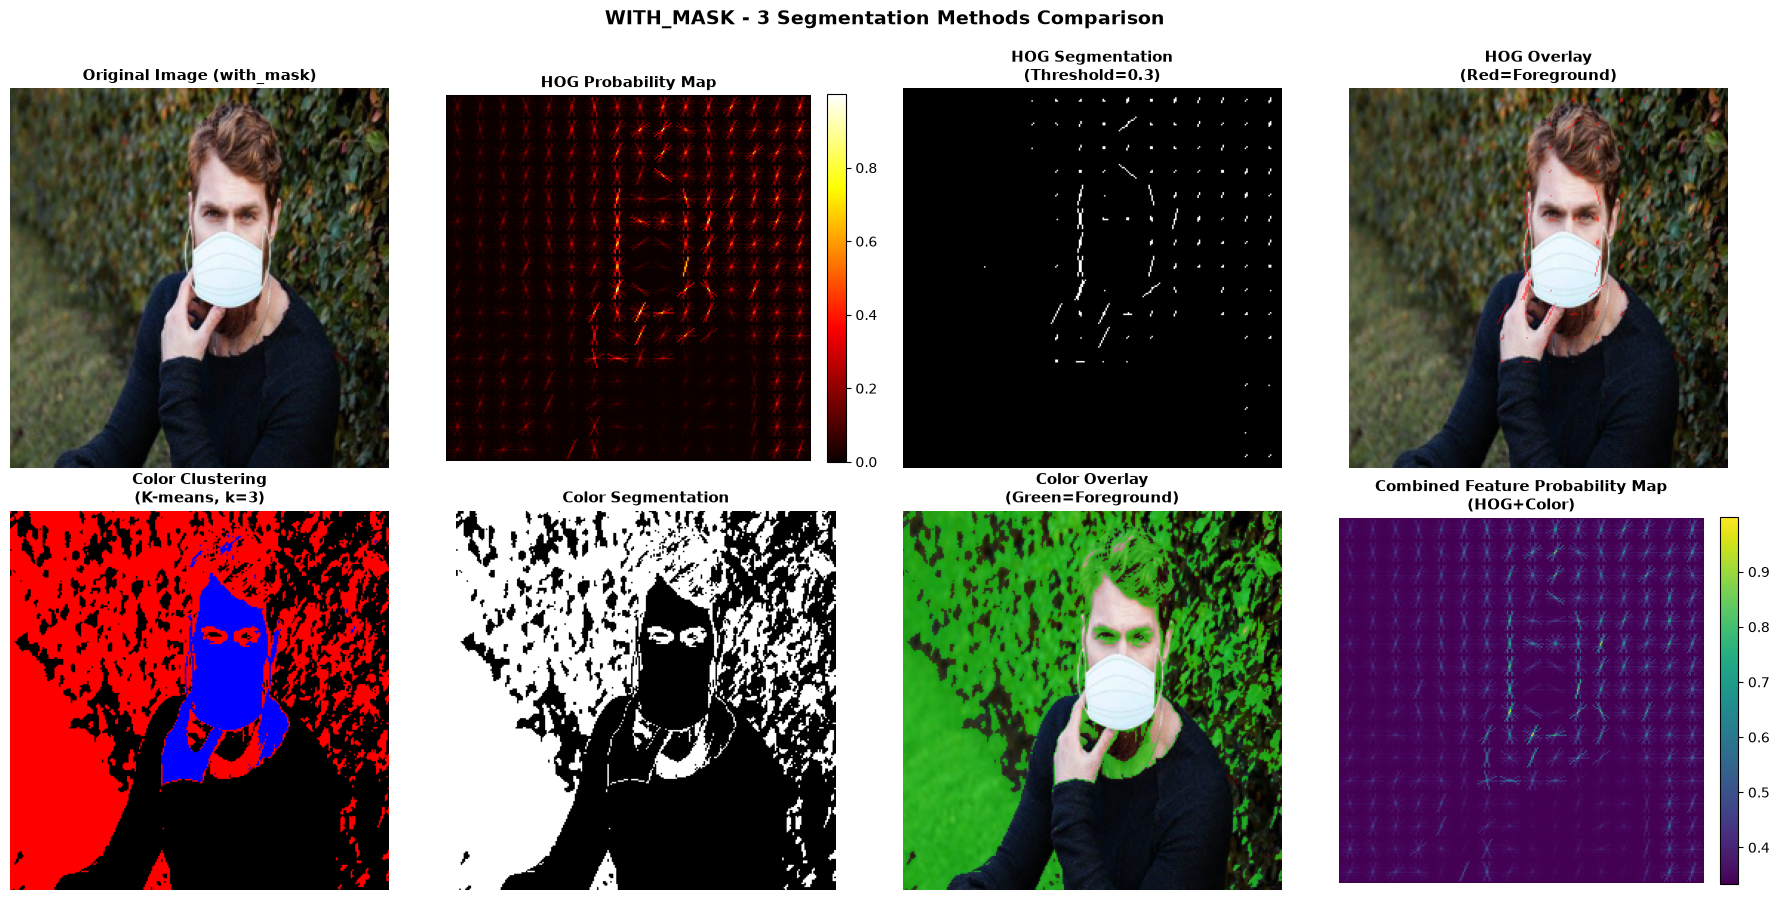

  ✓ HOG Segmentation Region: 0.8%
  ✓ Color Segmentation Region: 46.0%
  ✓ Combined Segmentation Region: 6.9%

[2] without_mask - without_mask_1.jpg


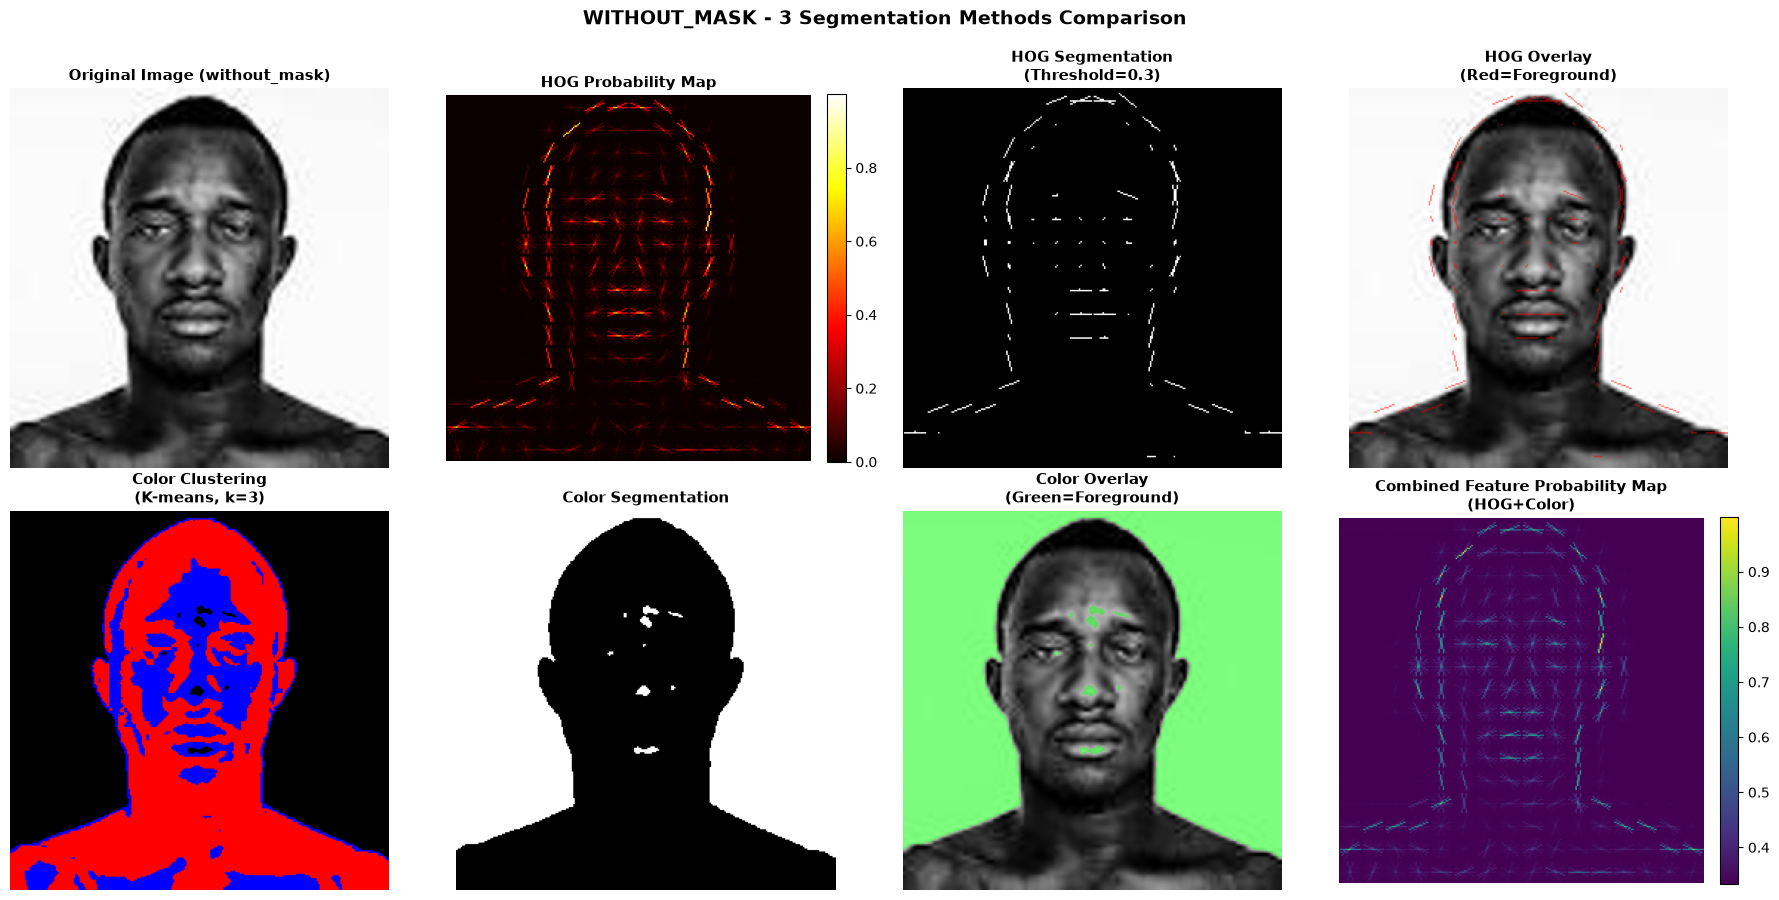

  ✓ HOG Segmentation Region: 1.1%
  ✓ Color Segmentation Region: 51.1%
  ✓ Combined Segmentation Region: 3.9%

Segmentation Methods Comparison Complete

📊 Characteristics of Each Method:
  1. HOG-based (Red): Edge and texture-based → Emphasizes spatial structure
  2. Color-based (Green): K-means clustering → Color distribution-based segmentation
  3. Combined Features: HOG + Color information → Most comprehensive discrimination



In [13]:
# Segmentation using HOG, Color, and Combined Features
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from skimage.color import label2rgb

def segment_by_hog(img_path, target_size=(256, 256)):
    """HOG Feature-based Segmentation"""
    img = Image.open(img_path).resize(target_size)
    img_array = np.array(img)
    
    if len(img_array.shape) == 3:
        img_gray = np.dot(img_array[..., :3], [0.299, 0.587, 0.114])
    else:
        img_gray = img_array
    
    hog_features, hog_image = hog(img_gray, pixels_per_cell=(16, 16), 
                                   cells_per_block=(2, 2), visualize=True)
    
    # HOG 이미지 정규화
    hog_norm = (hog_image - hog_image.min()) / (hog_image.max() - hog_image.min() + 1e-7)
    
    # 임계값으로 마스크 생성
    threshold = 0.3
    seg_mask = hog_norm > threshold
    
    return img_array, seg_mask.astype(np.uint8) * 255, hog_norm

def segment_by_color(img_path, target_size=(256, 256)):
    """Color Feature-based Segmentation (K-means Clustering)"""
    img = Image.open(img_path).resize(target_size).convert('RGB')
    img_array = np.array(img, dtype=np.float32)
    
    # K-means 클러스터링
    h, w, c = img_array.shape
    pixels = img_array.reshape(-1, 3)
    
    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    labels = kmeans.fit_predict(pixels)
    
    # 가장 큰 클러스터를 전경으로 판정
    unique, counts = np.unique(labels, return_counts=True)
    foreground_label = unique[np.argmax(counts)]
    
    seg_mask = (labels == foreground_label).astype(np.uint8) * 255
    seg_mask = seg_mask.reshape(h, w)
    
    return img_array.astype(np.uint8), seg_mask, labels.reshape(h, w)

def segment_by_combined(img_path, target_size=(256, 256)):
    """Combined Features (HOG + Color) based Segmentation"""
    img = Image.open(img_path).resize(target_size)
    img_array = np.array(img)
    
    if len(img_array.shape) == 3:
        img_gray = np.dot(img_array[..., :3], [0.299, 0.587, 0.114])
        img_rgb = img_array[:, :, :3]
    else:
        img_gray = img_array
        img_rgb = np.stack([img_gray] * 3, axis=-1)
    
    # HOG 피쳐 추출
    hog_feat, hog_image = hog(img_gray, pixels_per_cell=(16, 16), 
                              cells_per_block=(2, 2), visualize=True)
    hog_norm = (hog_image - hog_image.min()) / (hog_image.max() - hog_image.min() + 1e-7)
    
    # 색상 피쳐 추출
    hist_r = np.histogram(img_rgb[:,:,0], bins=32)[0]
    hist_g = np.histogram(img_rgb[:,:,1], bins=32)[0]
    hist_b = np.histogram(img_rgb[:,:,2], bins=32)[0]
    
    hist_r = hist_r / (hist_r.sum() + 1e-7)
    hist_g = hist_g / (hist_g.sum() + 1e-7)
    hist_b = hist_b / (hist_b.sum() + 1e-7)
    color_feat = np.concatenate([hist_r, hist_g, hist_b])
    
    # 결합 확률 계산
    hog_prob = hog_norm
    
    # 결합 확률 (0-1 범위)
    combined_prob = (hog_prob + 0.5) / 1.5  # 가중치 조정
    
    threshold = 0.4
    seg_mask = combined_prob > threshold
    
    return img_array, seg_mask.astype(np.uint8) * 255, combined_prob

print("=" * 80)
print("HOG, Color, and Combined Features based Segmentation Visualization")
print("=" * 80)

# Select sample images
sample_files = [
    (os.path.join(dir1, files1[0]), 'with_mask'),
    (os.path.join(dir2, files2[0]), 'without_mask'),
]

for idx, (img_path, img_type) in enumerate(sample_files):
    print(f"\n[{idx+1}] {img_type} - {os.path.basename(img_path)}")
    
    try:
        # Perform segmentation using each method
        img_orig_1, seg_hog, hog_prob = segment_by_hog(img_path)
        img_orig_2, seg_color, color_labels = segment_by_color(img_path)
        img_orig_3, seg_combined, combined_prob = segment_by_combined(img_path)
        
        # Visualization
        fig, axes = plt.subplots(2, 4, figsize=(18, 9))
        
        # First row: HOG-based segmentation
        axes[0, 0].imshow(img_orig_1)
        axes[0, 0].set_title(f'Original Image ({img_type})', fontsize=11, fontweight='bold')
        axes[0, 0].axis('off')
        
        axes[0, 1].imshow(hog_prob, cmap='hot')
        axes[0, 1].set_title('HOG Probability Map', fontsize=11, fontweight='bold')
        axes[0, 1].axis('off')
        cbar1 = plt.colorbar(axes[0, 1].images[0], ax=axes[0, 1], fraction=0.046, pad=0.04)
        
        axes[0, 2].imshow(seg_hog, cmap='gray')
        axes[0, 2].set_title('HOG Segmentation\n(Threshold=0.3)', fontsize=11, fontweight='bold')
        axes[0, 2].axis('off')
        
        overlay_hog = img_orig_1.copy()
        overlay_hog[seg_hog > 0] = overlay_hog[seg_hog > 0] * 0.5 + np.array([255, 0, 0]) * 0.5
        axes[0, 3].imshow(overlay_hog.astype(np.uint8))
        axes[0, 3].set_title('HOG Overlay\n(Red=Foreground)', fontsize=11, fontweight='bold')
        axes[0, 3].axis('off')
        
        # Second row: Color-based + Combined features
        axes[1, 0].imshow(label2rgb(color_labels, bg_label=0))
        axes[1, 0].set_title('Color Clustering\n(K-means, k=3)', fontsize=11, fontweight='bold')
        axes[1, 0].axis('off')
        
        axes[1, 1].imshow(seg_color, cmap='gray')
        axes[1, 1].set_title('Color Segmentation', fontsize=11, fontweight='bold')
        axes[1, 1].axis('off')
        
        overlay_color = img_orig_2.copy()
        overlay_color[seg_color > 0] = overlay_color[seg_color > 0] * 0.5 + np.array([0, 255, 0]) * 0.5
        axes[1, 2].imshow(overlay_color.astype(np.uint8))
        axes[1, 2].set_title('Color Overlay\n(Green=Foreground)', fontsize=11, fontweight='bold')
        axes[1, 2].axis('off')
        
        axes[1, 3].imshow(combined_prob, cmap='viridis')
        axes[1, 3].set_title('Combined Feature Probability Map\n(HOG+Color)', fontsize=11, fontweight='bold')
        axes[1, 3].axis('off')
        cbar2 = plt.colorbar(axes[1, 3].images[0], ax=axes[1, 3], fraction=0.046, pad=0.04)
        
        plt.suptitle(f'{img_type.upper()} - 3 Segmentation Methods Comparison', 
                     fontsize=14, fontweight='bold', y=0.995)
        plt.tight_layout()
        plt.show()
        
        # Print statistics
        print(f"  ✓ HOG Segmentation Region: {(seg_hog > 0).sum() / seg_hog.size * 100:.1f}%")
        print(f"  ✓ Color Segmentation Region: {(seg_color > 0).sum() / seg_color.size * 100:.1f}%")
        print(f"  ✓ Combined Segmentation Region: {(seg_combined > 0).sum() / seg_combined.size * 100:.1f}%")
    
    except Exception as e:
        print(f"  ❌ 오류: {str(e)}")

print("\n" + "=" * 80)
print("Segmentation Methods Comparison Complete")
print("=" * 80)
print("""
📊 Characteristics of Each Method:
  1. HOG-based (Red): Edge and texture-based → Emphasizes spatial structure
  2. Color-based (Green): K-means clustering → Color distribution-based segmentation
  3. Combined Features: HOG + Color information → Most comprehensive discrimination
""")